In [9]:
import pandas as pd
import numpy as np

from pathlib import Path
import warnings


In [10]:
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

PROJECT_ROOT = Path("..").resolve()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
METADATA_DIR = PROJECT_ROOT / "data" / "metadata"

METADATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)

Project root: C:\Users\cjc72\Desktop\DeliveryLate\AI-Retail-Demand-Intelligence
Raw data directory: C:\Users\cjc72\Desktop\DeliveryLate\AI-Retail-Demand-Intelligence\data\raw


### Load Datasets

In [11]:
# Load data
sales = pd.read_csv(
    RAW_DATA_DIR / "sales_train_evaluation.csv"
)

calendar = pd.read_csv(
    RAW_DATA_DIR / "calendar.csv"
)

sell_prices = pd.read_csv(
    RAW_DATA_DIR / "sell_prices.csv"
)

print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)
print("Sell prices shape:", sell_prices.shape)

Sales shape: (30490, 1947)
Calendar shape: (1969, 14)
Sell prices shape: (6841121, 4)


### Inspect datasets

In [12]:
datasets = {
    "sales": sales,
    "calendar": calendar,
    "sell_prices": sell_prices
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name.upper()}")

    print("\nShape:")
    print(df.shape)

    print("\nData types:")
    print(df.dtypes.value_counts())

    print("\nMissing values:")
    print(df.isnull().sum().sort_values(ascending=False).head(20))

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

    print("\nMemory usage:")
    print(f"{df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")


DATASET: SALES

Shape:
(30490, 1947)

Data types:
int64    1941
str         6
Name: count, dtype: int64

Missing values:
id          0
item_id     0
dept_id     0
cat_id      0
store_id    0
state_id    0
d_1         0
d_2         0
d_3         0
d_4         0
d_5         0
d_6         0
d_7         0
d_8         0
d_9         0
d_10        0
d_11        0
d_12        0
d_13        0
d_14        0
dtype: int64

Duplicate rows:
0

Memory usage:
454.74 MB

DATASET: CALENDAR

Shape:
(1969, 14)

Data types:
str      7
int64    7
Name: count, dtype: int64

Missing values:
event_type_2    1964
event_name_2    1964
event_name_1    1807
event_type_1    1807
date               0
wm_yr_wk           0
year               0
month              0
wday               0
weekday            0
d                  0
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

Duplicate rows:
0

Memory usage:
0.26 MB

DATASET: SELL_PRICES

Shape:
(6841121, 4)

Data types:
str        2
int64  

### Sales table metadata

In [13]:
metadata_columns = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

sales_metadata = sales[metadata_columns]

for column in metadata_columns:
    print(
        f"{column}: "
        f"{sales_metadata[column].nunique():,} unique values"
    )

print("\nSample records:")
display(sales[metadata_columns].head())

id: 30,490 unique values
item_id: 3,049 unique values
dept_id: 7 unique values
cat_id: 3 unique values
store_id: 10 unique values
state_id: 3 unique values

Sample records:


,id,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA


In [14]:
sales_columns = [
    column for column in sales.columns
    if column.startswith("d_")
]

sales_columns = sorted(
    sales_columns,
    key=lambda column: int(column.split("_")[1])
)

print("Number of daily sales columns:", len(sales_columns))
print("First day:", sales_columns[0])
print("Last day:", sales_columns[-1])


Number of daily sales columns: 1941
First day: d_1
Last day: d_1941


In [15]:
calendar["date"] = pd.to_datetime(calendar["date"])

calendar_check = calendar[
    calendar["d"].isin([
        "d_1",
        "d_1913",
        "d_1941",
        "d_1969"
    ])
][["d", "date", "wm_yr_wk", "weekday", "month", "year"]]

display(calendar_check)

,d,date,wm_yr_wk,weekday,month,year
0,d_1,2011-01-29,11101,Saturday,1,2011
1912,d_1913,2016-04-24,11613,Sunday,4,2016
1940,d_1941,2016-05-22,11617,Sunday,5,2016
1968,d_1969,2016-06-19,11621,Sunday,6,2016


### Syntetos–Boylan Demand Pattern Classification

Used **Syntetos–Boylan demand classification** to categorize product-store sales patterns based on demand frequency and variability. This helps identify which products have regular, irregular, or intermittent demand, to evaluate forecasting performance across different demand patterns.

The classification uses two measures:

- **ADI (Average Demand Interval):** The average number of periods between non-zero demand occurrences, measured over the active period.
- **CV² (Squared Coefficient of Variation):** The variance of non-zero demand quantities divided by their squared mean. It measures the variability of demand size.

The two measures divide demand patterns into four categories:

| Demand Pattern | ADI | CV² | Description |
|---|---:|---:|---|
| Smooth | < 1.32 | < 0.49 | Frequent and relatively stable demand |
| Erratic | < 1.32 | ≥ 0.49 | Frequent but highly variable demand |
| Intermittent | ≥ 1.32 | < 0.49 | Infrequent but relatively stable demand sizes |
| Lumpy | ≥ 1.32 | ≥ 0.49 | Infrequent and highly variable demand |

**Purpose in this project:** to understand the characteristics of our product-store time series, support representative dataset sampling, and compare forecasting performance across different demand patterns. This helps determine whether certain models perform better on specific types of demand.

In [16]:
# Convert daily sales into a NumPy matrix.
# Shape: (number of item-store series, number of days)

sales_matrix = sales[sales_columns].to_numpy(dtype=np.float32)

number_of_series, number_of_days = sales_matrix.shape

print("Sales matrix shape:", sales_matrix.shape)

# Store results
series_results = []

for index, row in sales.iterrows():

    demand = sales_matrix[index]

    nonzero_positions = np.flatnonzero(demand > 0)
    nonzero_demand = demand[nonzero_positions]

    if len(nonzero_positions) == 0:
        first_demand_day = np.nan
        active_period = 0
        adi = np.nan
        cv2 = np.nan

    else:
        first_demand_day = int(nonzero_positions[0] + 1)
        last_demand_day = int(nonzero_positions[-1] + 1)

        # Active period: first non-zero sale through last non-zero sale
        active_period = last_demand_day - first_demand_day + 1

        # ADI: active periods divided by number of non-zero demands
        adi = active_period / len(nonzero_demand)

        # CV²: variance / mean² of non-zero demand sizes
        mean_demand = nonzero_demand.mean()

        if mean_demand > 0:
            cv2 = np.var(nonzero_demand, ddof=0) / (mean_demand ** 2)
        else:
            cv2 = np.nan

    series_results.append({
        "id": row["id"],
        "item_id": row["item_id"],
        "dept_id": row["dept_id"],
        "cat_id": row["cat_id"],
        "store_id": row["store_id"],
        "state_id": row["state_id"],
        "first_demand_day": first_demand_day,
        "active_period": active_period,
        "nonzero_days": len(nonzero_positions),
        "zero_days_active": active_period - len(nonzero_positions),
        "adi": adi,
        "cv2": cv2
    })

series_classes = pd.DataFrame(series_results)

display(series_classes.head())

Sales matrix shape: (30490, 1941)


,id,item_id,dept_id,cat_id,store_id,state_id,first_demand_day,active_period,nonzero_days,zero_days_active,adi,cv2
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,902,1040,436,604,2.3853,0.2829
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,144,1798,408,1390,4.4069,0.2338
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,1106,836,229,607,3.6507,0.2879
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,37,1905,1316,589,1.4476,0.5830
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,113,1829,983,846,1.8606,0.4004


In [17]:
# Assign Demand Classes based on ADI and CV² thresholds
def classify_demand(row):

    adi = row["adi"]
    cv2 = row["cv2"]

    if pd.isna(adi) or pd.isna(cv2):
        return "no_demand"

    if adi < 1.32 and cv2 < 0.49:
        return "smooth"

    elif adi < 1.32 and cv2 >= 0.49:
        return "erratic"

    elif adi >= 1.32 and cv2 < 0.49:
        return "intermittent"

    else:
        return "lumpy"


series_classes["demand_class"] = series_classes.apply(
    classify_demand,
    axis=1
)

display(
    series_classes["demand_class"]
    .value_counts()
    .rename_axis("demand_class")
    .to_frame("series_count")
)

,series_count
demand_class,
intermittent,22155
lumpy,5572
smooth,1903
erratic,860


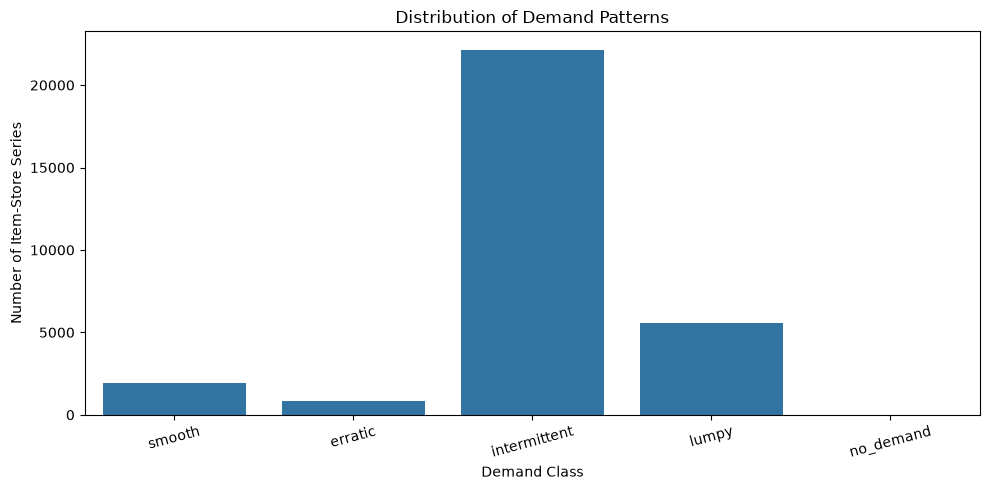

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = (
    series_classes["demand_class"]
    .value_counts()
    .reindex(
        ["smooth", "erratic", "intermittent", "lumpy", "no_demand"],
        fill_value=0
    )
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Demand Patterns")
plt.xlabel("Demand Class")
plt.ylabel("Number of Item-Store Series")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Save as parquet for efficient process

In [20]:
output_path = METADATA_DIR / "series_classes.parquet"

series_classes.to_parquet(
    output_path,
    index=False
)

print("Saved:", output_path)

Saved: C:\Users\cjc72\Desktop\DeliveryLate\AI-Retail-Demand-Intelligence\data\metadata\series_classes.parquet
